# Data feasibility checks

AMZN Level 10, 21 June 2012. Reproduces the checks used in the feasibility review; no model training.

Run all cells using the assignment Python environment. Notebook dependencies are listed in `requirements-notebook.txt`.

In [1]:
from pathlib import Path
from datetime import timedelta
import io, json, sys, unittest
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.data import DataLoader
get_ipython().run_line_magic("matplotlib", "inline")

data_folder = "LOBSTER_SampleFile_AMZN_2012-06-21_10"
parents, suffixes = (Path.cwd(), *Path.cwd().parents), (".", "2.7", "Project/2.7")
topic = next((p / s for p in parents for s in suffixes if (p / s / data_folder).is_dir()), None)
assert topic is not None, "Run from COMP3710/Project/2.7 or a nearby project folder."
project, data_dir = topic / "PatternAnalysis-2026/recognition/timegan_spagheddy7", topic / data_folder
sys.path.insert(0, str(project))
from dataset import PRICE_COLUMNS, VOLUME_COLUMNS, load_raw, prepare_datasets, decode_features

saved = json.loads((project / "reports/data_audit.json").read_text())
pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 150)
pd.set_option("display.precision", 8)
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | Data: {data_folder}")

Python 3.12.14 | PyTorch 2.8.0+cu128 | Data: LOBSTER_SampleFile_AMZN_2012-06-21_10


Load all rows from both CSVs. The file hashes must match the original audit.

In [2]:
book, times, audit = load_raw(data_dir)
message_path = next(data_dir.glob("*_message_10.csv"))
messages = np.loadtxt(message_path, delimiter=",", dtype=np.float64, ndmin=2)
saved_files = {item["name"]: item for item in saved["files"]}
file_rows = []
for item in audit["files"]:
    array = messages if "_message_" in item["name"] else book
    kind = "Message" if array is messages else "Order book"
    matches = item["sha256"] == saved_files[item["name"]]["sha256"]
    file_rows.append((kind, *array.shape, item["bytes"] / 2**20, matches))
files = pd.DataFrame(file_rows, columns=["File", "Rows", "Columns", "Size (MiB)", "Matches saved hash"])
display(files.set_index("File"))
assert messages.shape == (len(book), 6) and book.shape[1] == 40
assert files["Matches saved hash"].all()

,Rows,Columns,Size (MiB),Matches saved hash
File,,,,
Message,269748,6,10.72764397,True
Order book,269748,40,60.28770638,True


Full-dataset integrity checks. Counts are violations; zero is the expected result. Events are not replayed to reconstruct the book.

In [3]:
asks, bids, prices, volumes = book[:, 0::4], book[:, 2::4], book[:, PRICE_COLUMNS], book[:, VOLUME_COLUMNS]
start, end = audit["session_seconds"]
checks = [
    ("Non-finite message values", np.count_nonzero(~np.isfinite(messages)), "Values"),
    ("Backward timestamps", np.count_nonzero(np.diff(times) < 0), "Transitions"),
    ("Timestamps outside session", np.count_nonzero((times < start) | (times > end)), "Rows"),
    ("Missing-level placeholders", np.count_nonzero(np.abs(prices) >= 9999999999), "Price entries"),
    ("Non-positive prices", np.count_nonzero(prices <= 0), "Price entries"),
    ("Negative quantities", np.count_nonzero(volumes < 0), "Quantity entries"),
    ("Crossed or locked books", np.count_nonzero(asks[:, 0] <= bids[:, 0]), "Rows"),
    ("Unordered ask ladders", np.count_nonzero(np.any(np.diff(asks, axis=1) <= 0, axis=1)), "Rows"),
    ("Unordered bid ladders", np.count_nonzero(np.any(np.diff(bids, axis=1) >= 0, axis=1)), "Rows"),
    ("Trading halts", np.count_nonzero(messages[:, 1] == 7), "Rows"),
]
integrity = pd.DataFrame(checks, columns=["Check", "Violations", "Count unit"]).set_index("Check")
display(integrity)
assert integrity["Violations"].eq(0).all()
assert audit["raw_integrity"] == saved["raw_integrity"]
print(f"Checked {len(book):,} snapshots and {prices.size:,} prices / {volumes.size:,} quantities.")

,Violations,Count unit
Check,,
Non-finite message values,0,Values
Backward timestamps,0,Transitions
Timestamps outside session,0,Rows
Missing-level placeholders,0,Price entries
Non-positive prices,0,Price entries
Negative quantities,0,Quantity entries
Crossed or locked books,0,Rows
Unordered ask ladders,0,Rows
Unordered bid ladders,0,Rows


Checked 269,748 snapshots and 5,394,960 prices / 5,394,960 quantities.


Event counts across the complete message file.

In [4]:
labels = {1: "New order", 2: "Partial cancellation", 3: "Deletion", 4: "Visible execution", 5: "Hidden execution", 7: "Halt"}
types, counts = np.unique(messages[:, 1].astype(int), return_counts=True)
events = pd.DataFrame({"Code": types, "Event": [labels.get(t, "Other") for t in types], "Count": counts})
display(events.set_index("Code"))
assert dict(zip(map(str, types), map(int, counts))) == saved["event_type_counts"]

,Event,Count
Code,,
1,New order,131954
2,Partial cancellation,2917
3,Deletion,123458
4,Visible execution,8974
5,Hidden execution,2445


Split 70/15/15 by elapsed session time. Each split needs one starting snapshot; complete sequences contain 32 updates with stride 32.

In [5]:
sequence_length, stride = 32, 32
datasets, scaler, report = prepare_datasets(data_dir, sequence_length=sequence_length, stride=stride)
split_rows = []
for name, data in datasets.items():
    states, updates, sequences = len(data.book), len(data.features), len(data)
    split_rows.append((name, states, updates, updates // sequence_length, sequences, updates % sequence_length))
    assert updates == states - 1 and sequences == updates // sequence_length
    assert sequences == saved["splits"][name]["windows"]
    assert np.isfinite(data.features).all()
columns = ["Split", "Snapshots", "Updates", "Updates // 32", "Sequences", "Unused updates"]
display(pd.DataFrame(split_rows, columns=columns).set_index("Split"))
cuts = [str(timedelta(seconds=int(t))) for t in report["cut_times_seconds"]]
print(f"Split boundaries: {' and '.join(cuts)} (dataset market time).")
print("Each sequence has shape (32, 40); no sequence crosses a split boundary.")
assert report["splits"] == saved["splits"]
assert np.allclose(scaler.minimum, saved["scaler"]["minimum"]) and np.allclose(scaler.maximum, saved["scaler"]["maximum"])

,Snapshots,Updates,Updates // 32,Sequences,Unused updates
Split,,,,,
train,176255,176254,5507,5507,30
validation,34624,34623,1081,1081,31
test,58869,58868,1839,1839,20


Split boundaries: 14:03:00 and 15:01:30 (dataset market time).
Each sequence has shape (32, 40); no sequence crosses a split boundary.


Reverse preprocessing on the first real training sequence only. Small errors reflect floating-point storage.

In [6]:
example = datasets["train"][0]
restored = decode_features(example["features"].numpy(), scaler, example["initial_prices"].numpy())
expected = datasets["train"].book[1:sequence_length + 1].astype(np.float64)
expected[:, PRICE_COLUMNS] /= 10000
price_error = np.max(np.abs(restored[:, PRICE_COLUMNS] - expected[:, PRICE_COLUMNS]))
volume_error = np.max(np.abs(restored[:, VOLUME_COLUMNS] - expected[:, VOLUME_COLUMNS]))
display(pd.DataFrame({"Quantity": ["Price (USD)", "Volume (shares)"], "Maximum absolute error": [price_error, volume_error]}))
np.testing.assert_allclose(restored[:, PRICE_COLUMNS], expected[:, PRICE_COLUMNS], rtol=0, atol=1e-5)
np.testing.assert_allclose(restored[:, VOLUME_COLUMNS], expected[:, VOLUME_COLUMNS], rtol=1e-5, atol=1e-3)
np.testing.assert_allclose(price_error, saved["training_round_trip"]["max_price_error_usd"], rtol=1e-6, atol=1e-12)
np.testing.assert_allclose(volume_error, saved["training_round_trip"]["max_volume_error_shares"], rtol=1e-6, atol=1e-12)

,Quantity,Maximum absolute error
0,Price (USD),0.00000026
1,Volume (shares),0.00127362


Transfer one batch. Input size and GPU capacity are reported; peak training memory has not been measured.

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch = next(iter(DataLoader(datasets["train"], batch_size=64, shuffle=False)))
features = batch["features"].to(device)
gpu_name = torch.cuda.get_device_name() if device.type == "cuda" else "CPU; GPU check not performed"
capacity = torch.cuda.get_device_properties(0).total_memory / 2**30 if device.type == "cuda" else np.nan
batch_mib = features.numel() * features.element_size() / 2**20
gpu_row = [(gpu_name, str(tuple(features.shape)), batch_mib, capacity)]
display(pd.DataFrame(gpu_row, columns=["Device", "Batch shape", "Input size (MiB)", "GPU capacity (GiB)"]))
assert torch.isfinite(features).all().item()
assert list(features.shape) == saved["device_check"]["batch_shape"]
assert batch_mib == saved["device_check"]["batch_memory_mib"]
if device.type == "cuda":
    torch.cuda.synchronize()
print("Batch transfer and finite-value check passed. No model training was run.")

,Device,Batch shape,Input size (MiB),GPU capacity (GiB)
0,NVIDIA GeForce RTX 4060 Laptop GPU,"(64, 32, 40)",0.3125,7.99560547


Batch transfer and finite-value check passed. No model training was run.


Five existing pipeline tests use small synthetic datasets. They test splitting, scaling, reconstruction and rejection of invalid inputs.

In [8]:
test_log = io.StringIO()
suite = unittest.defaultTestLoader.discover(str(project), pattern="test_dataset.py", top_level_dir=str(project))
result = unittest.TextTestRunner(stream=test_log, verbosity=2).run(suite)
print(test_log.getvalue())
assert result.testsRun == 5 and result.wasSuccessful()

test_inverse_transform_reconstructs_each_split (test_dataset.DatasetChecks.test_inverse_transform_reconstructs_each_split) ... ok
test_mismatched_row_counts_are_rejected (test_dataset.DatasetChecks.test_mismatched_row_counts_are_rejected) ... ok
test_missing_levels_are_not_treated_as_real_prices (test_dataset.DatasetChecks.test_missing_levels_are_not_treated_as_real_prices) ... ok
test_scaling_does_not_learn_or_clip_future_volume_extremes (test_dataset.DatasetChecks.test_scaling_does_not_learn_or_clip_future_volume_extremes) ... ok
test_split_before_windowing_and_equal_timestamps_stay_together (test_dataset.DatasetChecks.test_split_before_windowing_and_equal_timestamps_stay_together) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.257s

OK



Preview the first 2,000 training snapshots. The horizontal axis counts events, not equally spaced seconds.

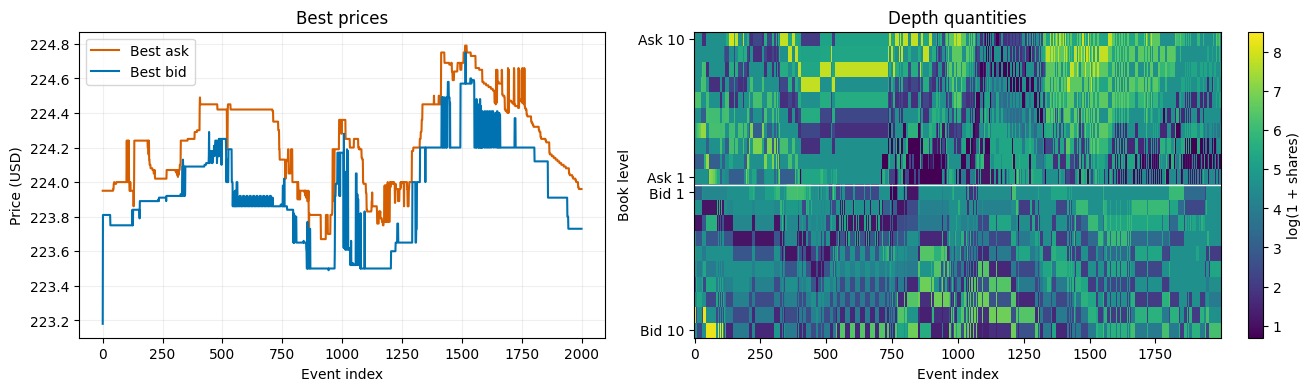

In [9]:
sample = datasets["train"].book[:2000]
depth = np.concatenate((sample[:, 1::4][:, ::-1], sample[:, 3::4]), axis=1).T
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
axes[0].plot(sample[:, 0] / 10000, label="Best ask", color="#d55e00")
axes[0].plot(sample[:, 2] / 10000, label="Best bid", color="#0072b2")
axes[0].set(title="Best prices", xlabel="Event index", ylabel="Price (USD)")
axes[0].legend(loc="best")
axes[0].grid(alpha=0.2)
heatmap = axes[1].imshow(np.log1p(depth), aspect="auto", cmap="viridis", interpolation="nearest")
axes[1].set(title="Depth quantities", xlabel="Event index", ylabel="Book level")
axes[1].set_yticks([0, 9, 10, 19], ["Ask 10", "Ask 1", "Bid 1", "Bid 10"])
axes[1].axhline(9.5, color="white", linewidth=1)
fig.colorbar(heatmap, ax=axes[1], label="log(1 + shares)")
plt.show()
plt.close(fig)

Checks reproduce the original audit. They establish data integrity and loading, not model quality or training feasibility.

Sources: `dataset.py`, `test_dataset.py`, `reports/data_audit.json` and the supplied LOBSTER format notes.

I Coded with AI assistance